<a href="https://colab.research.google.com/github/yevheniiareutska/python_for_ds_tasks/blob/main/HW_11_1_%D0%92%D1%96%D0%B7%D1%83%D0%B0%D0%BB%D1%96%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%B4%D0%B0%D0%BD%D0%B8%D1%85_%D0%B7_Pandas_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Візуалізація даних з Pandas

## Опис завдання
У цьому домашньому завданні ви працюватимете з датасетом про оренду велосипедів `yulu_rental.csv`. Датасет містить інформацію про кількість орендованих велосипедів залежно від погодних умов, сезону та інших факторів.
Набір даних взяти з Kaggle. Посилання на оригінальний [опис](https://www.kaggle.com/datasets/ranitsarkar01/yulu-bike-sharing-data?select=yulu_bike_sharing_dataset.csv).

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів



---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.


Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

## Підготовка даних


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Завантаження даних
df = pd.read_csv('/content/drive/MyDrive/data/yulu_rental.csv')

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Перетворення datetime у правильний формат
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour

## Завдання 0: Перегляд даних
**Завдання:**
Перегляньте дані, їх розмір, та напишіть висновок:
- скільки даних в наборі
- який рівень деталізації мають ці дані, тобто за який період міститься дані в одному рядку даних ?

In [4]:
df.head(20) #Дані мають погодинну деталізацію:

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour
datetime,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2
2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3
2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1,2011-01-01,1,52,5,Saturday,2011,1,4
2011-01-01 05:00:00,1,0,0,2,9.84,12.880,75,6.0032,0,1,1,2011-01-01,1,52,5,Saturday,2011,1,5
2011-01-01 06:00:00,1,0,0,1,9.02,13.635,80,0.0000,2,0,2,2011-01-01,1,52,5,Saturday,2011,1,6
2011-01-01 07:00:00,1,0,0,1,8.20,12.880,86,0.0000,1,2,3,2011-01-01,1,52,5,Saturday,2011,1,7
2011-01-01 08:00:00,1,0,0,1,9.84,14.395,75,0.0000,1,7,8,2011-01-01,1,52,5,Saturday,2011,1,8


In [5]:
df.count() #в наборі 10886 рядків = 10886 даних

,0
season,10886
holiday,10886
workingday,10886
weather,10886
temp,10886
atemp,10886
humidity,10886
windspeed,10886
casual,10886
registered,10886


## Завдання 1: Базовий лінійний графік

**Завдання:**
1. Згрупуйте дані про кількість орендованих велосипедів (`count`) поденно.
2. Побудуйте з методом `DataFrame.plot()` лінійний графік поденної кількості орендованих велосипедів (`count`) за весь період в даних.
3. Налаштуйте розмір графіка (12x6), додайте заголовок "Динаміка оренди велосипедів" та сітку.
4. Дайте відповіді на питання по цьому графіку. Якщо треба - проведіть додаткові програмні операції для відповідей.

**Питання для інтерпретації:**
1. Як гадаєте, чому графік має "заломи", чим це спричинено і як ви б могли прибрати заломи?
2. Які загальні тенденції ви бачите на графіку?
3. Чи помітні якісь сезонні коливання?
4. Чи є періоди з аномально високими або низькими значеннями і чому на ваш погляд можуть бути ці аномалії?


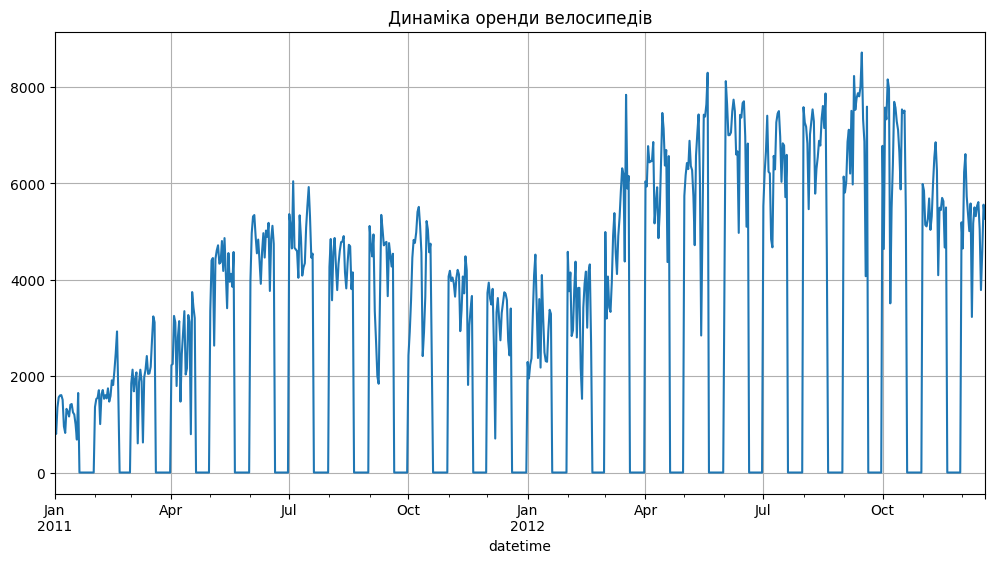

In [33]:
daily = df['count'].resample('D').sum()
daily.plot(
    figsize=(12, 6),
    title='Динаміка оренди велосипедів',
    grid=True);

1. Заломи виникають через те що деякі дані дорівнюють 0 або іх немає у нашому датасеті. Щоби це прибрати можна поставити умову щоби на графіку були тільки значення більше 0

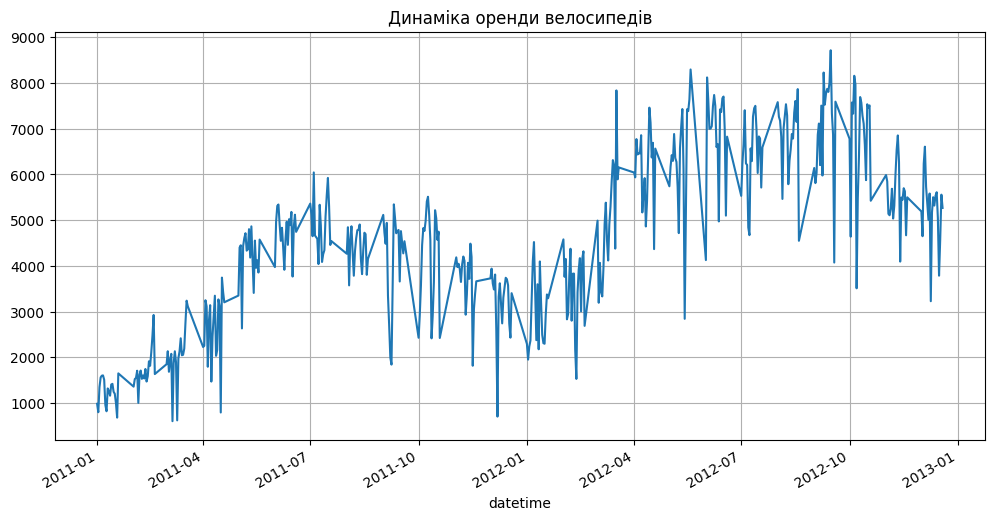

In [34]:
daily = df['count'].resample('D').sum()
daily = daily[daily > 0]
daily.plot(
    figsize=(12, 6),
    title='Динаміка оренди велосипедів',
    grid=True);

2. У 2012 році кількість орендованих велосипедів помітно зростає
3. Взимку кількість орендованих велосипедів маленька,в той час влітку кількість набагато зростає,це може бути тому що гарна погода і більше людей проводять час на вулиці та обирають кататись на велосипедах.

In [8]:
# 4 найнижчі значення можуть бути тому що це була зима та мало покупців або коли сервіс тільки почав працювати
# найбільші тому що це літо та багато людей орендували велосипеди через гарну погоду
print(daily.nsmallest(10))
print(daily.nlargest(10))

datetime
2011-03-06     605
2011-03-10     623
2011-01-18     683
2011-12-07     705
2011-04-16     795
2011-01-02     801
2011-01-09     822
2011-01-08     959
2011-01-01     985
2011-01-17    1000
Name: count, dtype: int64
datetime
2012-09-15    8714
2012-05-19    8294
2012-09-09    8227
2012-10-05    8156
2012-06-02    8120
2012-09-14    8009
2012-10-06    7965
2012-09-12    7870
2012-08-18    7865
2012-03-17    7836
Name: count, dtype: int64



## Завдання 2: Аналіз сезонності (Bar Plot)

**Завдання:**
Побудуйте вертикальну стовпчасту діаграму середньої кількості орендованих велосипедів за сезонами(кварталами). Додайте підписи осей і заголовок.

Просунуте доповнення:
1. Позначте квартали не числом, а назвою на візуалізації.
2. Додайте підписи над стовпцями зі значеннями в кожному стовпці.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В який квартал найбільша середня кількість оренди велосипедів?
2. Як ви можете пояснити таку сезонну закономірність?
3. У скільки разів відрізняється оренда між найпопулярнішим та найменш популярним кварталми?

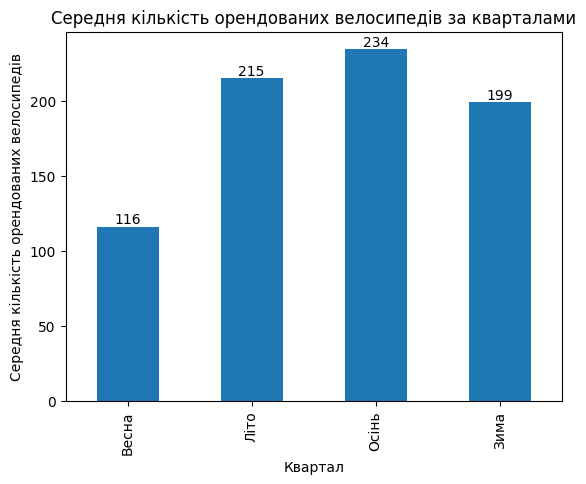

In [32]:
mean_number = df.groupby('season')['count'].mean()
mean_number.index = ['Весна', 'Літо', 'Осінь', 'Зима']
ax = mean_number.plot.bar(
    title='Середня кількість орендованих велосипедів за кварталами',
    ylabel = 'Середня кількість орендованих велосипедів',
    xlabel = 'Квартал')
ax.bar_label(ax.containers[0], fmt='%.0f');

1. Найбільша середня кількість восени
2. Це може бути через гарну погоду тому люди проводили багато часу на вулиці
3. 234/116 = 2
В два рази

## Завдання 3: Динаміка за місяцями (Line Plot)

**Завдання:**
Створіть лінійний графік середньої кількості оренд велосипедів на годину по місяцях (тобто групування в рамках місяця і беремо середню кількість оренд у цей місяць з кількох років). Використайте маркери-кружечки для точок, додайте сітку та пофарбуйте лінію у червоний колір.

Просунуте доповнення:
- додайте аби по осі ОХ поділки були чітко на кожен окремий місяць по одній. Тобто сумарно 12 поділок.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які місяці спостерігається пік та спад оренди?
2. Чи збігається ця закономірність з результатами з попереднього завдання?
3. Як може вплинути клімат на оренду велосипедів протягом року?


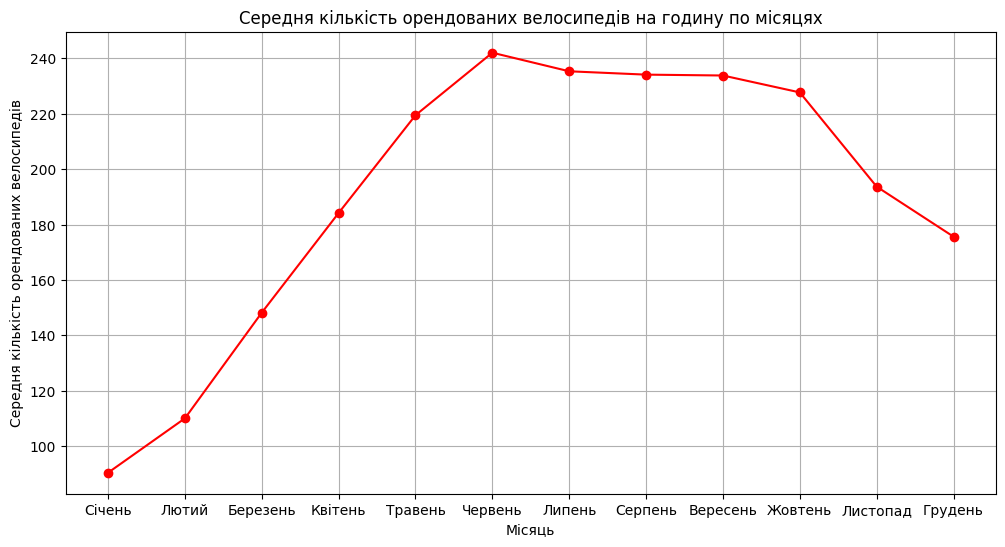

In [31]:
mean_by_month = df.groupby('month')['count'].mean()
mean_by_month.index = ['Січень', 'Лютий', 'Березень', 'Квітень', 'Травень', 'Червень', 'Липень', 'Серпень', 'Вересень', 'Жовтень', 'Листопад', 'Грудень']
mean_by_month.plot(
    title='Середня кількість орендованих велосипедів на годину по місяцях',
    ylabel = 'Середня кількість орендованих велосипедів',
    xlabel = 'Місяць',
    figsize = (12,6),
    marker='o',
    grid=True,
    xticks=range(12),
    color='red'
);

1. Пік - червень, спад - січень та грудень
2. Так, у літку кількість орендованих велосипедів набагато більша за зиму
3. Літом тепло та довгий день, тому попит оренди великий.
Взимку холодно сніг та рано темніє т

## Завдання 4: Розподіл погодних умов (Pie Chart)

**Завдання:**
1. Побудуйте кругову діаграму з часткою записів за погодними умовами
2. Додайте підписи з відсотками та легенду з описами погоди (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ).
3. Визначте свої відмінні від стандартних кольори для відображення кожної категорії.
4. Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. Яка погода переважає в датасеті?
2. Чи є дні із сильним дощем? Яка їх частка?
3. Як ви думаєте, як погодні умови впливають на попит на оренду велосипедів?

Очікуваний результат:

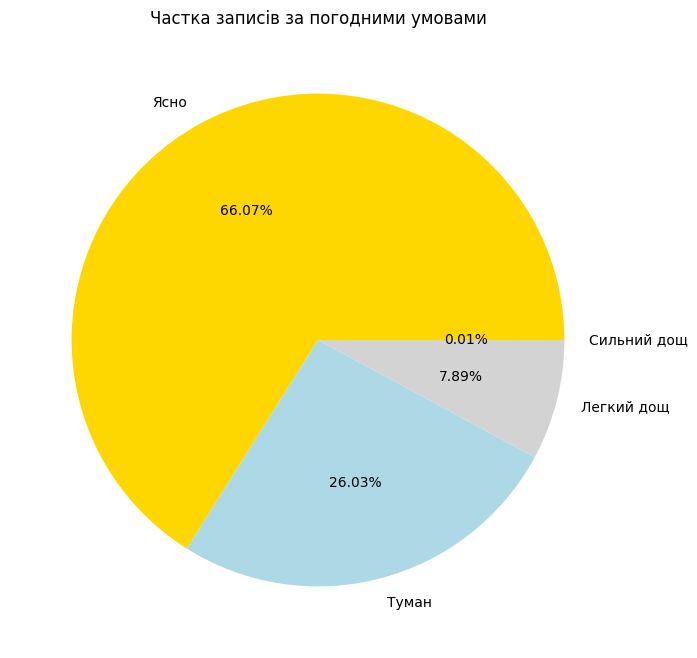

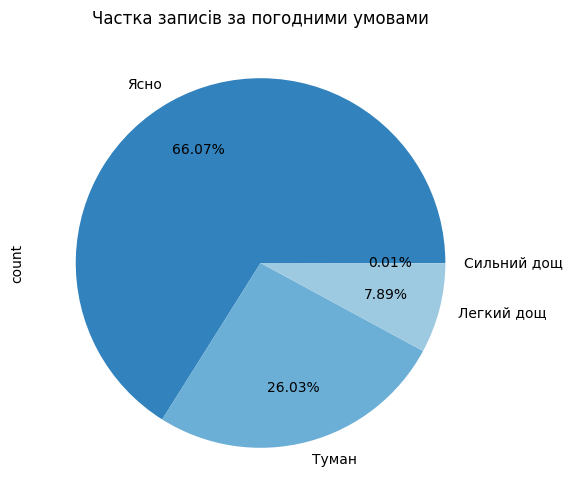

In [35]:
weather_counts = df['weather'].value_counts().sort_index()

labels = [ 'Ясно','Туман', 'Легкий дощ', 'Сильний дощ']

diagram = weather_counts.plot.pie(
    labels=labels,
    autopct='%1.2f%%',
    colors=plt.cm.tab20c.colors,
    startangle=0,
    labeldistance=1.1,
    pctdistance=0.7,
    figsize = (12,6),
    title='Частка записів за погодними умовами'
);

1. Ясна погода
2. Так, 0.01%
3. Коли погода тепла більше людей їздять на велосипедах, а коли дощ та туман люди не обирають заннятя на вулиці

## Завдання 5: Box Plot для аналізу викидів

**Завдання:**
Створіть коробковий графік (box plot) кількості орендованих велосипедів для кожного типу погоди.

Просунуте доповнення:
- Використайте горизонтальну орієнтацію.
- Позначте погодні умови не числом, а назвою на візуалізації.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. При якій погоді найбільший розкид у кількості оренди?
2. Чи є викиди (outliers) в даних? При якій погоді?
3. При якій погоді медіанне значення оренди найвище?

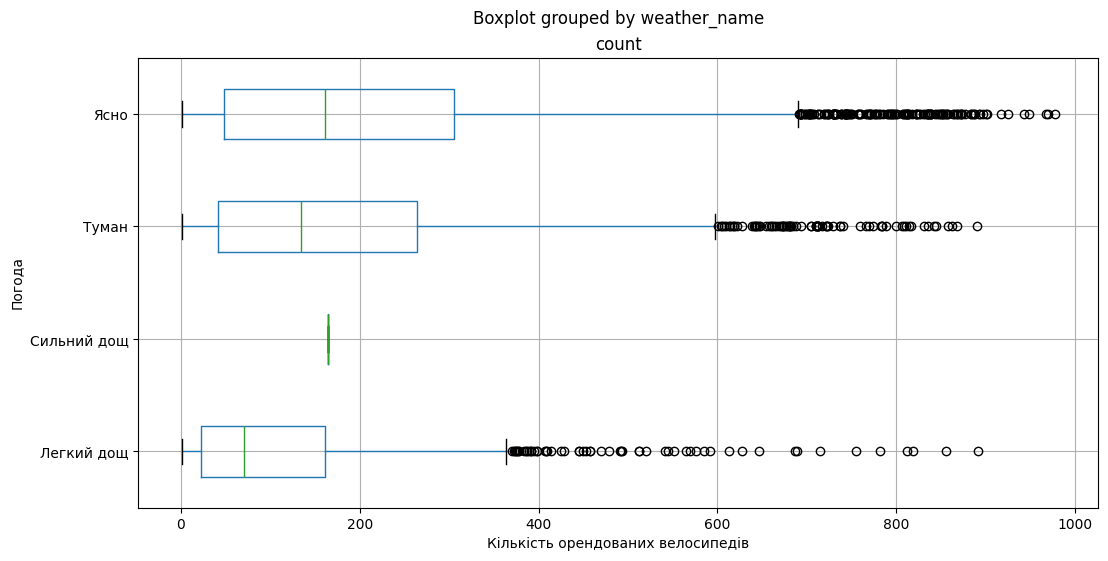

In [39]:
df['weather_name'] = df['weather'].map({
    1: 'Ясно',
    2: 'Туман',
    3: 'Легкий дощ',
    4: 'Сильний дощ'
})

df.boxplot(column='count',
           by='weather_name',
           figsize=(12, 6),
           xlabel = 'Кількість орендованих велосипедів',
           ylabel = 'Погода',
           vert=False);

1. При ясній погоді
2. Так, коли ясно, туман і легкий дощ
3. При ясній погоді

## Завдання 6: Кореляція температури та оренди (Scatter Plot)

**Завдання:**
Побудуйте діаграму розсіювання залежності між температурою (`temp`) та загальною кількістю оренди (`count`). Розфарбуйте точки за сезонами, додайте напівпрозорість (alpha=0.6).

**Увага!** За замовченням буде колір

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
- Чи є зв'язок між температурою та кількістю оренди? Який?

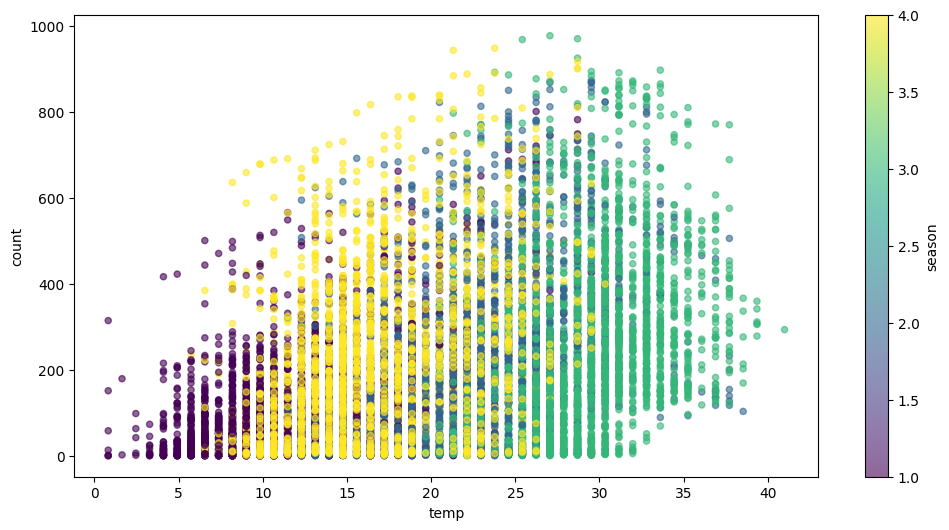

In [20]:
df.plot.scatter(
    x='temp',
    y='count',
    c='season',
    alpha=0.6,
    colormap='viridis',
    figsize=(12, 6));

Кореляція між температурою та кількостью позитивна, тобто коли температура зростає кількість орендовних велосипедів також зростає

## (Опціонально) Завдання 7: Порівняння користувачів (Stacked Bar Chart)

**Завдання:**
Ми хочемо дізнатись як по дням тижня беруть в середньому в оренду велосипеди випадкові і зареєстровані користувачі.

Створіть стовпчасту діаграму з накопиченням (bar з налаштуванням `stacked=True`), яка показує співвідношення випадкових (`casual`) та зареєстрованих (`registered`) користувачів по днях тижня за кількістю взятих ними велосипедів в оренду в середньому. Використайте різні кольори для типів користувачів.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які дні тижня більше оренд від зареєстрованих користувачів?
2. Як ви можете пояснити таку різницю в поведінці користувачів протягом тижня?

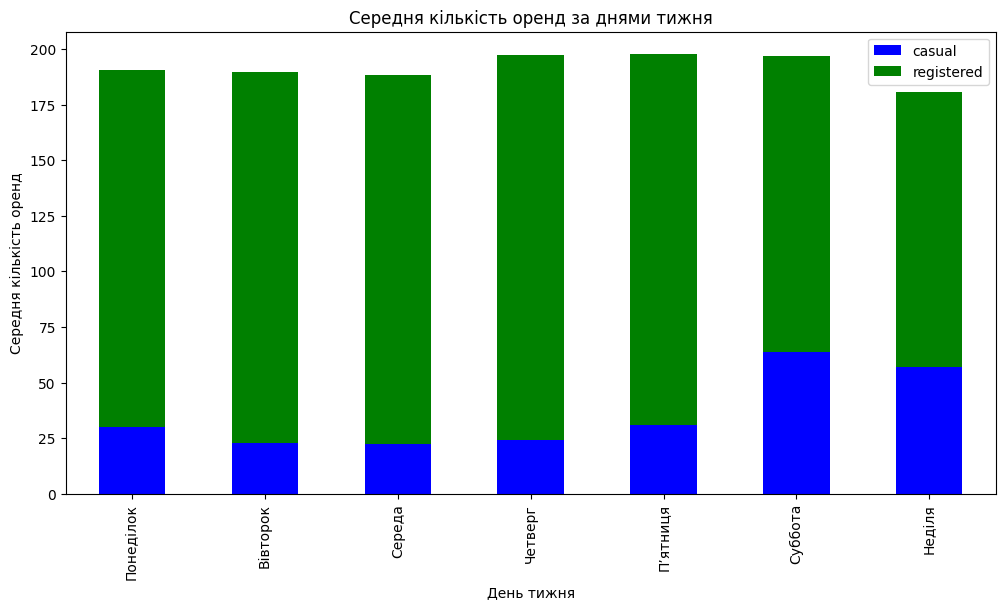

In [41]:
avg = df.groupby('weekday')[['casual', 'registered']].mean()
avg.index = ['Понеділок', 'Вівторок', 'Середа', 'Четверг', 'Пʼятниця', 'Суббота', 'Неділя']

avg.plot.bar(
    stacked=True,
    color=['blue', 'green'],
    figsize=(12, 6),
    title='Середня кількість оренд за днями тижня',
    xlabel='День тижня',
    ylabel='Середня кількість оренд');


1. Більше оренд від ареєстрованих користувачів у четвер, вівторок та пʼятницю
2.  Зареєстровані користувачі, це напевно постійні клієнти, які регулярно їздять на велосипеді, у той час коли випадкові користувачі беруть велосипеди для відпочинку й прогулянок, тому їхня оренда зростає на вихідних.